In [3]:
import pandas as pd
import numpy as np
import joblib
import shap

# Load trained model
xgb_model = joblib.load(
    "../models/xgboost_model.pkl"
)

# Load preprocessing pipeline
preprocessor = joblib.load(
    "../models/preprocessor.pkl"
)

# Load configuration
model_config = joblib.load(
    "../models/model_config.pkl"
)

print("Model loaded.")
print("Threshold:", model_config["threshold"])

c:\Users\Jofin Joseph\OneDrive\Desktop\FinGuard AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded.
Threshold: 0.4653724730014801


In [4]:
df = pd.read_csv(
    "../data/processed/transactions_model_ready.csv",
    low_memory=False
)

df["timestamp"] = pd.to_datetime(df["timestamp"])

test_df = df[
    df["timestamp"] >= "2026-09-01"
].copy()

print("Test records:", len(test_df))

Test records: 109811


In [5]:
target = "is_fraud"

drop_columns = [
    "transaction_id",
    "id",
    "user_id",
    "merchant_id",
    "device_id",
    "ip_address",
    "timestamp",
    "previous_timestamp",

    "device_user_count",
    "device_transaction_count",
    "location_transaction_count",
    "user_location_transaction_count",
    "user_merchant_transaction_count",
    "user_category_transaction_count",
    "new_merchant_for_user"
]

feature_columns = [
    col for col in df.columns
    if col not in drop_columns + [target]
]

X_test = test_df[feature_columns]
y_test = test_df[target]

print("X_test:", X_test.shape)

X_test: (109811, 19)


In [6]:
X_test_processed = preprocessor.transform(X_test)

print(
    "Processed test shape:",
    X_test_processed.shape
)

Processed test shape: (109811, 46)


In [7]:
sample_size = 1000

X_shap = X_test_processed[
    np.random.RandomState(42).choice(
        X_test_processed.shape[0],
        size=sample_size,
        replace=False
    )
]

print("SHAP sample:", X_shap.shape)

SHAP sample: (1000, 46)


**Model Explanability**

In [8]:
    # ==========================================
# SHAP EXPLAINER
# ==========================================

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated.")
print("Shape:", np.array(shap_values).shape)

SHAP values calculated.
Shape: (1000, 46)


In [9]:
# ==========================================
# FEATURE NAMES
# ==========================================

feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))

print("\nFirst 20 features:")
print(feature_names[:20])

Number of feature names: 46

First 20 features:
['numeric__amount' 'numeric__account_age' 'numeric__transaction_count_24h'
 'numeric__avg_transaction_amount' 'numeric__distance_from_home'
 'numeric__is_new_device' 'numeric__is_new_location'
 'numeric__flag_missing_amount' 'numeric__flag_negative_amount'
 'numeric__flag_missing_user' 'numeric__flag_missing_merchant'
 'numeric__flag_negative_distance' 'numeric__flag_duplicate_transaction'
 'numeric__flag_invalid_timestamp' 'numeric__flag_unknown_category'
 'numeric__data_quality_issue' 'numeric__missingindicator_amount'
 'numeric__missingindicator_distance_from_home'
 'numeric__missingindicator_is_new_device'
 'numeric__missingindicator_is_new_location']


In [10]:
# ==========================================
# GLOBAL SHAP IMPORTANCE
# ==========================================

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Top 20 features:")
print(shap_importance.head(20))

Top 20 features:
                                         feature  mean_abs_shap
0                                numeric__amount       1.492819
1                 numeric__transaction_count_24h       1.336653
2                         numeric__is_new_device       1.325297
3                       numeric__is_new_location       1.304627
4                numeric__avg_transaction_amount       0.572088
5     categorical__merchant_category_electronics       0.413771
6          categorical__merchant_category_travel       0.388852
7   categorical__merchant_category_entertainment       0.376691
8                    numeric__distance_from_home       0.145335
9       categorical__merchant_category_utilities       0.119108
10     categorical__merchant_category_healthcare       0.107173
11           categorical__merchant_category_fuel       0.106885
12       categorical__merchant_category_clothing       0.100078
13         categorical__merchant_category_retail       0.092173
14        categorical__

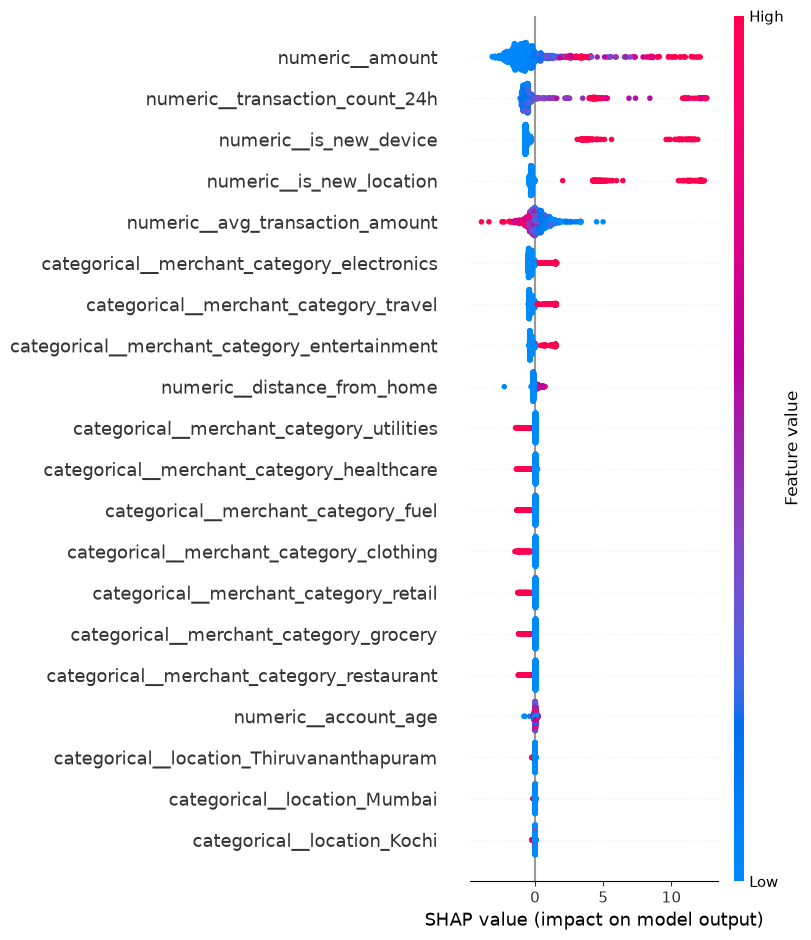

In [ ]:
# ==========================================
# SHAP SUMMARY PLOT
# ==========================================

import matplotlib.pyplot as plt
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=20
)

In [12]:
# ==========================================
# FIND A FRAUDULENT TEST TRANSACTION
# ==========================================

fraud_indices = np.where(y_test.values == 1)[0]

example_idx = fraud_indices[0]

X_example = X_test_processed[example_idx:example_idx + 1]

print("Example index:", example_idx)

Example index: 0


In [13]:
# ==========================================
# INDIVIDUAL SHAP EXPLANATION
# ==========================================

example_shap = explainer.shap_values(X_example)

print("SHAP explanation generated.")

SHAP explanation generated.


In [14]:
# ==========================================
# TOP FEATURES FOR THIS TRANSACTION
# ==========================================

example_explanation = pd.DataFrame({
    "feature": feature_names,
    "shap_value": example_shap[0],
    "impact": np.abs(example_shap[0])
})

example_explanation = (
    example_explanation
    .sort_values("impact", ascending=False)
    .reset_index(drop=True)
)

print(example_explanation.head(15))

                                         feature  shap_value    impact
0                 numeric__transaction_count_24h    4.655956  4.655956
1                       numeric__is_new_location    4.443516  4.443516
2                         numeric__is_new_device    3.875901  3.875901
3                                numeric__amount    2.180874  2.180874
4                numeric__avg_transaction_amount   -0.620140  0.620140
5                    numeric__distance_from_home    0.421102  0.421102
6                           numeric__account_age    0.096256  0.096256
7      categorical__merchant_category_healthcare    0.089855  0.089855
8                   categorical__location_Mumbai   -0.079906  0.079906
9          categorical__merchant_category_travel   -0.047413  0.047413
10  categorical__merchant_category_entertainment   -0.045030  0.045030
11      categorical__location_Thiruvananthapuram    0.039560  0.039560
12    categorical__merchant_category_electronics    0.028666  0.028666
13    

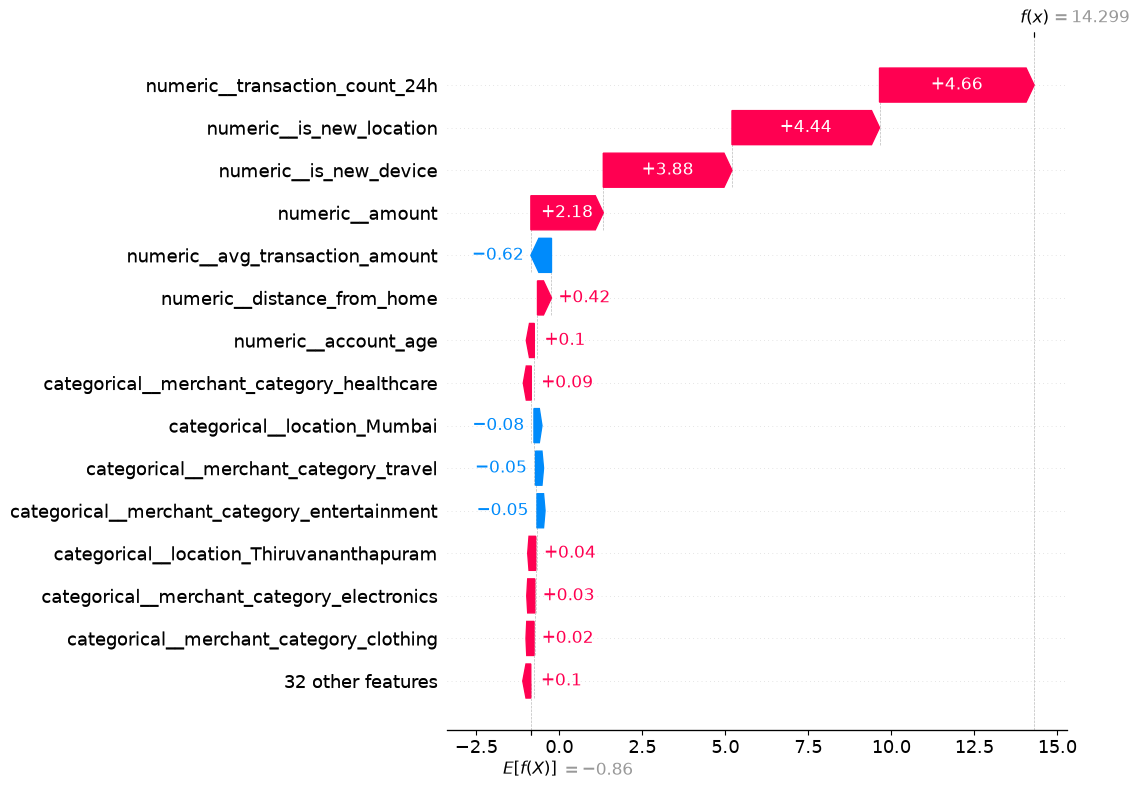

In [15]:
shap.waterfall_plot(
    shap.Explanation(
        values=example_shap[0],
        feature_names=feature_names,
        base_values=explainer.expected_value
    ),
    max_display=15
)

In [17]:
# ==========================================
# HUMAN-READABLE FEATURE NAMES
# ==========================================

def clean_feature_name(feature):
    name = feature.replace("numeric__", "")
    name = name.replace("categorical__", "")

    replacements = {
        "transaction_count_24h": "Transaction velocity (24h)",
        "is_new_device": "New device",
        "is_new_location": "New location",
        "amount": "Transaction amount",
        "avg_transaction_amount": "Average transaction amount",
        "distance_from_home": "Distance from home",
        "account_age": "Account age",
        "amount_deviation_ratio": "Amount deviation",
        "amount_zscore": "Amount z-score",
        "seconds_since_previous": "Time since previous transaction",
        "rapid_transaction": "Rapid transaction",
        "user_transaction_history": "Transaction history",
        "long_distance_transaction": "Long-distance transaction",
        "day_of_week": "Day of week",
        "hour": "Transaction hour",
        "is_weekend": "Weekend transaction"
    }

    for key, readable in replacements.items():
        if name == key:
            return readable

    # Handle one-hot categories
    if name.startswith("merchant_category_"):
        category = name.replace("merchant_category_", "")
        return f"Merchant category: {category}"

    if name.startswith("location_"):
        location = name.replace("location_", "")
        return f"Location: {location}"

    if name.startswith("payment_method_"):
        method = name.replace("payment_method_", "")
        return f"Payment method: {method}"

    return name.replace("_", " ").title()


readable_feature_names = [
    clean_feature_name(feature)
    for feature in feature_names
]

print(readable_feature_names[:20])

['Transaction amount', 'Account age', 'Transaction velocity (24h)', 'Average transaction amount', 'Distance from home', 'New device', 'New location', 'Flag Missing Amount', 'Flag Negative Amount', 'Flag Missing User', 'Flag Missing Merchant', 'Flag Negative Distance', 'Flag Duplicate Transaction', 'Flag Invalid Timestamp', 'Flag Unknown Category', 'Data Quality Issue', 'Missingindicator Amount', 'Missingindicator Distance From Home', 'Missingindicator Is New Device', 'Missingindicator Is New Location']


In [18]:
# ==========================================
# FINGUARD TRANSACTION EXPLANATION
# ==========================================

def explain_transaction(processed_transaction):
    
    # Model probability
    probability = xgb_model.predict_proba(
        processed_transaction
    )[0, 1]

    threshold = model_config["threshold"]

    # Risk classification
    if probability >= threshold:
        risk_level = "HIGH"
    elif probability >= 0.25:
        risk_level = "MEDIUM"
    else:
        risk_level = "LOW"

    # SHAP explanation
    shap_value = explainer.shap_values(
        processed_transaction
    )[0]

    explanation = pd.DataFrame({
        "feature": readable_feature_names,
        "shap_value": shap_value
    })

    explanation["impact"] = explanation["shap_value"].abs()

    # Only features increasing fraud risk
    risk_factors = (
        explanation[
            explanation["shap_value"] > 0
        ]
        .sort_values("shap_value", ascending=False)
        .head(5)
    )

    reasons = risk_factors["feature"].tolist()

    return {
        "fraud_probability": float(probability),
        "risk_score": float(probability * 100),
        "risk_level": risk_level,
        "reasons": reasons
    }

In [19]:
result = explain_transaction(X_example)

print("===== FINGUARD EXPLANATION =====")

print(
    f"Fraud probability: "
    f"{result['fraud_probability'] * 100:.2f}%"
)

print(
    f"Risk score: "
    f"{result['risk_score']:.2f}/100"
)

print(
    f"Risk level: "
    f"{result['risk_level']}"
)

print("\nMain reasons:")

for reason in result["reasons"]:
    print("•", reason)

===== FINGUARD EXPLANATION =====
Fraud probability: 100.00%
Risk score: 100.00/100
Risk level: HIGH

Main reasons:
• Transaction velocity (24h)
• New location
• New device
• Transaction amount
• Distance from home
